# Notebook 05 — Multimodal / Vision-Language Model Evaluation

**Stage 6 | Temporal Vision / HMDB51 subset**

This notebook adds a small, inference-only VLM experiment and covers **all five requested capabilities**:

1. Sequence-level description.
2. Temporal change analysis.
3. Semantic action labeling.
4. Identification of ambiguous observations.
5. Comparison between early and later observations.

## Model selection

Use **Qwen2.5-VL-3B-Instruct, 4-bit MLX quantization** (`mlx-community/Qwen2.5-VL-3B-Instruct-4bit`) with `mlx-vlm` on Apple Silicon. The model weights are approximately 3.07 GB on disk; runtime memory is higher because of the vision encoder, activations, image processing and KV cache. This is a much more appropriate starting point for a 16 GB Apple Silicon machine than a 7B/large full-precision VLM.

No fine-tuning is performed. The notebook samples up to five chronological source frames per video, runs a small pilot, then optionally processes the full held-out test split. It saves raw responses, parsed structured fields, latency, errors, model provenance, capability summaries, and a per-video comparison with the visual classifiers.

**Important:** the VLM needs original frame images. It cannot perform image understanding from CLIP/SigLIP embedding vectors alone. The notebook resolves image paths from the saved frame manifest and stops clearly if those paths are unavailable.


## 1. Imports and MLX runtime check

In [1]:
import os, re, json, time, random, platform, hashlib, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
from IPython.display import display

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

try:
    import mlx.core as mx
    from mlx_vlm import load, generate
    from mlx_vlm.prompt_utils import apply_chat_template
    from mlx_vlm.utils import load_config
except Exception as exc:
    raise RuntimeError(
        "MLX VLM is not available in this Jupyter kernel. Run "
        "%pip install -U mlx-vlm pillow pandas matplotlib, restart the kernel, "
        "then rerun. Original error: " + repr(exc)
    )

print("Python:", platform.python_version())
print("MLX:", getattr(mx, "__version__", "installed"))
print("Apple Silicon MLX backend: available")


/Users/vanshikaarora/Desktop/Tracking/venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1101 01:43:25.865000 63548 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Python: 3.11.15
MLX: 0.32.4
Apple Silicon MLX backend: available


## 2. Project paths and new output folder

In [2]:
PROJECT_ROOT = Path("/Users/vanshikaarora/Desktop/Tracking")
if not PROJECT_ROOT.exists():
    cwd = Path.cwd()
    if (cwd / "embeddings").exists() and (cwd / "Single-multiframe").exists():
        PROJECT_ROOT = cwd
    else:
        raise FileNotFoundError("Set PROJECT_ROOT to your Tracking project folder.")

EMBEDDINGS_ROOT = PROJECT_ROOT / "embeddings" / "embedding-store"
STAGE4_ROOT = PROJECT_ROOT / "Single-multiframe"
STAGE5_ROOT = PROJECT_ROOT / "Temporal-Evaluation"
OUTPUT_ROOT = PROJECT_ROOT / "VLM-Evaluation"

for name in ["Pilot", "VLM_Outputs", "Classifier_Comparison", "Analysis", "Logs"]:
    (OUTPUT_ROOT / name).mkdir(parents=True, exist_ok=True)

print("Project:", PROJECT_ROOT)
print("New results folder:", OUTPUT_ROOT)


Project: /Users/vanshikaarora/Desktop/Tracking
New results folder: /Users/vanshikaarora/Desktop/Tracking/VLM-Evaluation


## 3. Model configuration and memory-conscious settings

In [3]:
MODEL_ID = "mlx-community/Qwen2-VL-2B-Instruct-4bit"
MODEL_FAMILY = "Qwen2.5-VL-3B-Instruct"
QUANTIZATION = "4-bit MLX"
FRAMES_PER_VIDEO = 5
MAX_NEW_TOKENS = 320
TEMPERATURE = 0.0

PILOT_VIDEO_COUNT = 5
RUN_FULL_TEST_SET = True
MAX_TEST_VIDEOS = None  # Set e.g. 20 for a shorter run; None means all accessible test videos.

print("Model:", MODEL_ID)
print("Frame observations/video:", FRAMES_PER_VIDEO)
print("Pilot size:", PILOT_VIDEO_COUNT)
print("Full test evaluation:", RUN_FULL_TEST_SET)


Model: mlx-community/Qwen2-VL-2B-Instruct-4bit
Frame observations/video: 5
Pilot size: 5
Full test evaluation: True


## 4. Load the exact saved test split and frame manifest

In [4]:
split_path = STAGE4_ROOT / "data-splits" / "video_level_splits.csv"
manifest_path = EMBEDDINGS_ROOT / "clip" / "frame_manifest.csv"
if not split_path.exists():
    raise FileNotFoundError(f"Missing Notebook 03 split: {split_path}")
if not manifest_path.exists():
    raise FileNotFoundError(f"Missing CLIP frame manifest: {manifest_path}")

split_df = pd.read_csv(split_path, dtype={"video_id": str})
manifest = pd.read_csv(manifest_path)
print("Manifest columns:", manifest.columns.tolist())

def resolve_column(df, candidates, purpose, override=None):
    if override:
        if override not in df.columns:
            raise KeyError(f"{purpose} override '{override}' is missing.")
        return override
    for col in candidates:
        if col in df.columns:
            return col
    raise KeyError(f"Cannot find {purpose}. Available columns: {df.columns.tolist()}")

# Set an override here if your manifest uses different column names.
VIDEO_COL_OVERRIDE = None
LABEL_COL_OVERRIDE = None
FRAME_COL_OVERRIDE = None
IMAGE_PATH_COL_OVERRIDE = None

video_col = resolve_column(manifest, ["video_id", "video", "sequence_id", "video_name", "filename"], "video ID", VIDEO_COL_OVERRIDE)
label_col = resolve_column(manifest, ["label", "class", "class_name", "action", "category"], "label", LABEL_COL_OVERRIDE)
frame_col = resolve_column(manifest, ["frame_index", "frame_idx", "frame_number", "frame_id", "index"], "frame index", FRAME_COL_OVERRIDE)
image_path_col = resolve_column(manifest, ["frame_path", "image_path", "path", "filepath", "file_path"], "original image path", IMAGE_PATH_COL_OVERRIDE)

split_df["video_id"] = split_df["video_id"].astype(str)
split_df["label"] = split_df["label"].astype(str)
TEST_IDS = set(split_df.loc[split_df["split"] == "test", "video_id"])
LABELS = sorted(split_df["label"].unique().tolist())

manifest = manifest.copy()
manifest["_vid"] = manifest[video_col].astype(str)
manifest["_label"] = manifest[label_col].astype(str)
manifest["_frame"] = pd.to_numeric(manifest[frame_col], errors="coerce")
manifest["_path"] = manifest[image_path_col].astype(str)
if manifest["_frame"].isna().any():
    raise ValueError("Frame index column contains non-numeric values.")

print("Test split videos:", len(TEST_IDS))
print("Action classes:", LABELS)
print("Image path column:", image_path_col)


Manifest columns: ['embedding_row', 'video_id', 'label', 'frame_index', 'frame_position', 'timestamp_sec', 'frame_path']
Test split videos: 143
Action classes: ['brush_hair', 'cartwheel', 'catch', 'chew', 'clap', 'climb', 'climb_stairs', 'dive', 'draw_sword']
Image path column: frame_path


## 5. Resolve source images and build ordered test-video records

In [5]:
def resolve_path(value):
    p = Path(str(value)).expanduser()
    candidates = [p] if p.is_absolute() else [PROJECT_ROOT / p, Path.cwd() / p]
    for candidate in candidates:
        if candidate.exists() and candidate.is_file():
            return candidate.resolve()
    return None

records = []
missing = []
for vid, group in manifest[manifest["_vid"].isin(TEST_IDS)].groupby("_vid", sort=True):
    group = group.sort_values("_frame", kind="stable")
    labels = group["_label"].unique()
    if len(labels) != 1:
        raise ValueError(f"Inconsistent labels for {vid}: {labels}")
    frames = []
    for _, row in group.iterrows():
        p = resolve_path(row["_path"])
        if p is None:
            missing.append({"video_id": vid, "frame_index": int(row["_frame"]), "path": row["_path"]})
        else:
            frames.append({"frame_index": int(row["_frame"]), "path": str(p)})
    if len(frames) >= 2:
        records.append({"video_id": vid, "label": labels[0], "frames": frames})

pd.DataFrame(missing).to_csv(OUTPUT_ROOT / "Logs" / "missing_frame_paths.csv", index=False)
if not records:
    raise RuntimeError(
        "No original image paths were resolved. This VLM experiment needs image pixels, "
        "not embedding vectors. Check the manifest path column and path roots."
    )

print("Test videos with accessible images:", len(records))
print("Missing image paths:", len(missing))
print("Frame counts:", pd.Series([len(r["frames"]) for r in records]).value_counts().sort_index().to_dict())

def choose_frames(record, k=FRAMES_PER_VIDEO):
    frames = record["frames"]
    n = len(frames)
    idx = np.unique(np.rint(np.linspace(0, n - 1, min(k, n))).astype(int))
    return [frames[i] for i in idx]



Test videos with accessible images: 143
Missing image paths: 0
Frame counts: {7: 140, 8: 3}


## 6. Inspect sample frame sequences before inference

Video: #20_Rhythm_clap_u_nm_np1_fr_goo_0 | label: clap


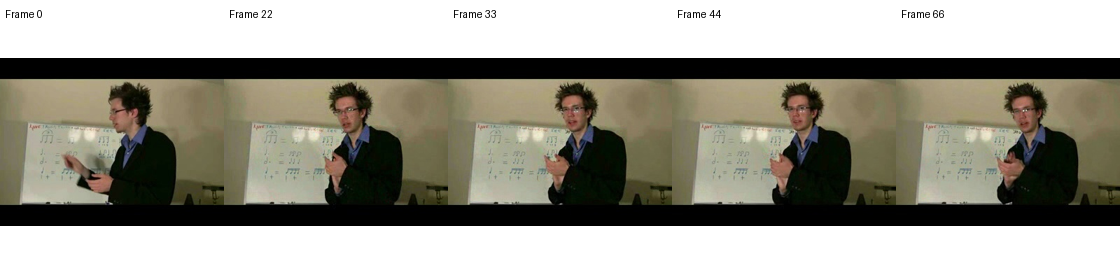

Video: 96_Meter_Bungy-Jump__Jauntal_02_dive_f_cm_np1_ri_bad_0 | label: dive


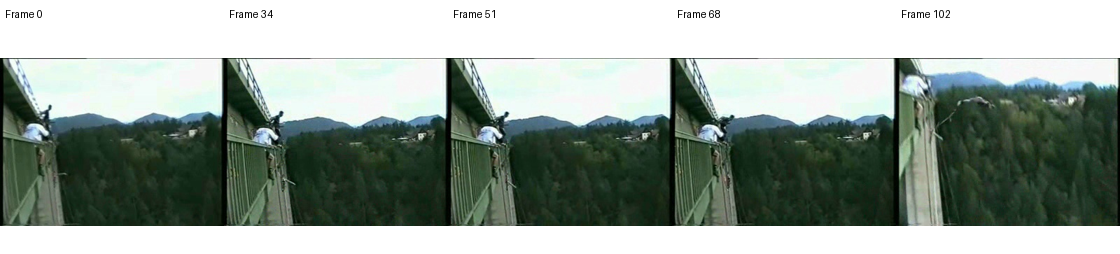

Video: A_Round_of_Applause_clap_u_cm_np1_fr_med_0 | label: clap


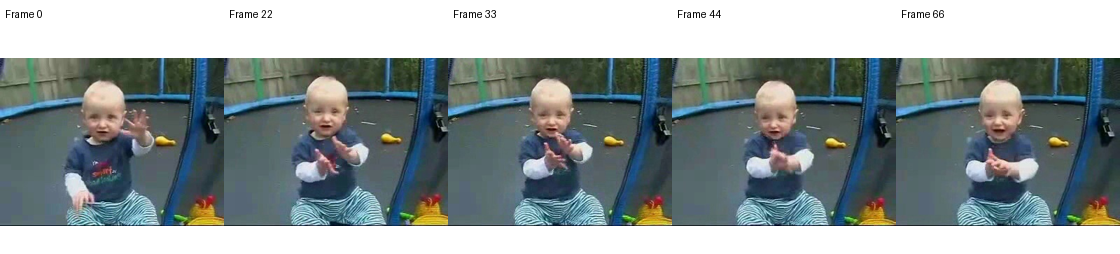

In [6]:
def contact_sheet(record, frame_rows=None, thumb=(224, 224)):
    frame_rows = frame_rows or choose_frames(record)
    sheet = Image.new("RGB", (thumb[0] * len(frame_rows), thumb[1] + 30), "white")
    draw = ImageDraw.Draw(sheet)
    for i, fr in enumerate(frame_rows):
        im = Image.open(fr["path"]).convert("RGB")
        im.thumbnail(thumb)
        x = i * thumb[0]
        sheet.paste(im, (x + (thumb[0] - im.width)//2, 30 + (thumb[1] - im.height)//2))
        draw.text((x + 5, 8), f"Frame {fr['frame_index']}", fill="black")
    return sheet

for rec in records[:3]:
    print("Video:", rec["video_id"], "| label:", rec["label"])
    display(contact_sheet(rec))


## 7. Load the 4-bit Qwen VLM

In [7]:
print("Loading:", MODEL_ID)
load_start = time.perf_counter()
model, processor = load(MODEL_ID)
model_config = load_config(MODEL_ID)
model_load_seconds = time.perf_counter() - load_start
print(f"Model loaded in {model_load_seconds:.1f} seconds.")


Loading: mlx-community/Qwen2-VL-2B-Instruct-4bit


Fetching 11 files: 100%|██████████| 11/11 [00:00<00:00, 2134.70it/s]

Model loaded in 335.4 seconds.


## 8. Structured prompt covering all five requested capabilities

In [8]:
ALLOWED_LABELS = LABELS + ["uncertain/other"]

PROMPT_TEMPLATE = '''
You are analyzing a short sequence of sampled video frames for an action-recognition research experiment.
The images are supplied in chronological order. Frame indices are provided below.
Use only visible evidence. Do not infer off-screen events or invent details.
Do not assume the action label from context. If evidence is insufficient, choose uncertain/other.
Separate direct visual observations from interpretations.

Return valid JSON only, with exactly these keys:
{
  "sequence_description": "concise description of the scene and visible activity",
  "temporal_changes": ["directly visible change between observations"],
  "semantic_label": "one allowed class label",
  "semantic_label_confidence": "low, medium, or high",
  "label_evidence": "visible evidence supporting the label",
  "ambiguous_observations": ["unclear, occluded, blurred, small, or ambiguous observations; [] if none"],
  "early_observation": "what is visible in the first one or two images",
  "later_observation": "what is visible in the last one or two images",
  "early_vs_later": "what additional information becomes visible later, or say no clear additional information",
  "uncertainty_notes": ["limitations or uncertainty; [] if none"]
}

Allowed semantic_label values: LABEL_OPTIONS
Do not output markdown fences or text outside the JSON object.
'''

def make_prompt(record, frame_rows):
    timeline = "; ".join([f"image {i+1}=source frame {fr['frame_index']}" for i, fr in enumerate(frame_rows)])
    return PROMPT_TEMPLATE.replace("LABEL_OPTIONS", ", ".join(ALLOWED_LABELS)) + (
        f"\nVideo ID: {record['video_id']}\n"
        f"Number of observations: {len(frame_rows)}\n"
        f"Chronological frame indices: {timeline}\n"
        "Analyze the images in the exact order supplied."
    )


## 9. Generation, JSON parsing and robust error capture

In [9]:
def raw_text(result):
    if isinstance(result, str):
        return result
    if hasattr(result, "text"):
        return str(result.text)
    if isinstance(result, dict):
        for key in ["text", "generated_text", "output"]:
            if key in result:
                return str(result[key])
    return str(result)

def parse_response(text):
    s = text.strip()
    s = re.sub(r"^```(?:json)?\s*", "", s, flags=re.I)
    s = re.sub(r"\s*```$", "", s)
    a, b = s.find("{"), s.rfind("}")
    if a < 0 or b <= a:
        return None, "No JSON object in response"
    try:
        obj = json.loads(s[a:b+1])
    except Exception as exc:
        return None, f"JSON parse error: {exc}"
    keys = [
        "sequence_description", "temporal_changes", "semantic_label",
        "semantic_label_confidence", "label_evidence", "ambiguous_observations",
        "early_observation", "later_observation", "early_vs_later", "uncertainty_notes"
    ]
    absent = [k for k in keys if k not in obj]
    return obj, ("Missing keys: " + ", ".join(absent)) if absent else None

def run_vlm(record):
    frame_rows = choose_frames(record)
    prompt = make_prompt(record, frame_rows)
    image_paths = [fr["path"] for fr in frame_rows]
    start = time.perf_counter()
    try:
        formatted = apply_chat_template(
            processor, model_config, prompt, num_images=len(image_paths)
        )
        # mlx-vlm supports a list of image paths for multi-image VLM input.
        result = generate(
            model, processor, formatted, image_paths,
            max_tokens=MAX_NEW_TOKENS, temp=TEMPERATURE
        )
        elapsed = time.perf_counter() - start
        text_out = raw_text(result)
        parsed, parse_error = parse_response(text_out)
        return {
            "video_id": record["video_id"], "ground_truth_label": record["label"],
            "frame_indices": [x["frame_index"] for x in frame_rows],
            "frame_paths": [x["path"] for x in frame_rows],
            "raw_response": text_out, "parsed": parsed,
            "parse_error": parse_error, "latency_seconds": elapsed,
            "status": "success" if parsed is not None and parse_error is None else "parse_error",
            "error": None
        }
    except Exception as exc:
        return {
            "video_id": record["video_id"], "ground_truth_label": record["label"],
            "frame_indices": [x["frame_index"] for x in frame_rows],
            "frame_paths": [x["path"] for x in frame_rows],
            "raw_response": None, "parsed": None, "parse_error": None,
            "latency_seconds": time.perf_counter() - start,
            "status": "error", "error": repr(exc)
        }

print("Multi-image generation wrapper ready.")


Multi-image generation wrapper ready.


## 10. Run a small pilot first

In [10]:
pilot_records = records[:min(PILOT_VIDEO_COUNT, len(records))]
pilot_results = []
for i, rec in enumerate(pilot_records, 1):
    print(f"Pilot {i}/{len(pilot_records)}: {rec['video_id']} ({rec['label']})")
    result = run_vlm(rec)
    pilot_results.append(result)
    print(result["status"], "| latency:", round(result["latency_seconds"], 2),
          "| parse:", result["parse_error"], "| error:", result["error"])

def flatten(results):
    rows = []
    for r in results:
        p = r.get("parsed") or {}
        rows.append({
            "video_id": r["video_id"], "ground_truth_label": r["ground_truth_label"],
            "frame_indices": json.dumps(r["frame_indices"]),
            "status": r["status"], "latency_seconds": r["latency_seconds"],
            "sequence_description": p.get("sequence_description"),
            "temporal_changes": json.dumps(p.get("temporal_changes", []), ensure_ascii=False),
            "semantic_label": p.get("semantic_label"),
            "semantic_label_confidence": p.get("semantic_label_confidence"),
            "label_evidence": p.get("label_evidence"),
            "ambiguous_observations": json.dumps(p.get("ambiguous_observations", []), ensure_ascii=False),
            "early_observation": p.get("early_observation"),
            "later_observation": p.get("later_observation"),
            "early_vs_later": p.get("early_vs_later"),
            "uncertainty_notes": json.dumps(p.get("uncertainty_notes", []), ensure_ascii=False),
            "parse_error": r.get("parse_error"), "error": r.get("error"),
            "raw_response": r.get("raw_response")
        })
    return pd.DataFrame(rows)

pilot_df = flatten(pilot_results)
pilot_df.to_csv(OUTPUT_ROOT / "Pilot" / "vlm_pilot_results.csv", index=False)
(OUTPUT_ROOT / "Pilot" / "vlm_pilot_raw.json").write_text(
    json.dumps(pilot_results, indent=2, ensure_ascii=False)
)
display(pilot_df[["video_id", "ground_truth_label", "status", "latency_seconds",
                  "semantic_label", "semantic_label_confidence", "parse_error", "error"]])


Pilot 1/5: #20_Rhythm_clap_u_nm_np1_fr_goo_0 (clap)
success | latency: 21.55 | parse: None | error: None
Pilot 2/5: 96_Meter_Bungy-Jump__Jauntal_02_dive_f_cm_np1_ri_bad_0 (dive)
parse_error | latency: 16.98 | parse: JSON parse error: Expecting ',' delimiter: line 10 column 167 (char 1129) | error: None
Pilot 3/5: A_Round_of_Applause_clap_u_cm_np1_fr_med_0 (clap)
success | latency: 12.3 | parse: None | error: None
Pilot 4/5: Acrobacias_de_un_fenomeno_cartwheel_f_cm_np1_fr_bad_5 (cartwheel)
success | latency: 13.53 | parse: None | error: None
Pilot 5/5: AgentCodyBanks_climb_stairs_f_cm_np1_fr_med_9 (climb_stairs)
success | latency: 16.68 | parse: None | error: None


,video_id,ground_truth_label,status,latency_seconds,semantic_label,semantic_label_confidence,parse_error,error
0,#20_Rhythm_clap_u_nm_np1_fr_goo_0,clap,success,21.553546,clap,high,NaN,None
1,96_Meter_Bungy-Jump__Jauntal_02_dive_f_cm_np1_...,dive,parse_error,16.983295,NaN,NaN,"JSON parse error: Expecting ',' delimiter: lin...",None
2,A_Round_of_Applause_clap_u_cm_np1_fr_med_0,clap,success,12.304007,clap,high,NaN,None
3,Acrobacias_de_un_fenomeno_cartwheel_f_cm_np1_f...,cartwheel,success,13.525919,cartwheel,high,NaN,None
4,AgentCodyBanks_climb_stairs_f_cm_np1_fr_med_9,climb_stairs,success,16.680112,uncertain/other,low,NaN,None


## 11. Pilot quality gate and qualitative inspection

In [11]:
pilot_valid_rate = float((pilot_df["status"] == "success").mean()) if len(pilot_df) else 0.0
print("Valid structured-output rate:", round(pilot_valid_rate, 3))
if pilot_valid_rate < 0.8:
    raise RuntimeError(
        "Pilot failed: fewer than 80% valid structured responses. Inspect pilot CSV, "
        "check MLX multi-image input, then rerun before the full test set."
    )

for _, row in pilot_df.head(3).iterrows():
    print("\n" + "="*90)
    print("Video:", row["video_id"], "| ground truth:", row["ground_truth_label"])
    print("VLM label:", row["semantic_label"], "| confidence:", row["semantic_label_confidence"])
    print("Description:", row["sequence_description"])
    print("Temporal changes:", row["temporal_changes"])
    print("Ambiguities:", row["ambiguous_observations"])
    print("Early:", row["early_observation"])
    print("Later:", row["later_observation"])
    print("Early vs later:", row["early_vs_later"])


Valid structured-output rate: 0.8

Video: #20_Rhythm_clap_u_nm_np1_fr_goo_0 | ground truth: clap
VLM label: clap | confidence: high
Description: A man is standing in front of a whiteboard, holding a piece of paper, and talking. The whiteboard has a music sheet on it.
Temporal changes: ["The man is holding a piece of paper, and the whiteboard is visible in the background."]
Ambiguities: ["The whiteboard is visible in the background, which could indicate that the man is in a classroom or a similar setting."]
Early: The man is holding a piece of paper, and the whiteboard is visible in the background.
Later: The man is talking, and the whiteboard is still visible in the background.
Early vs later: The man is holding a piece of paper, and the whiteboard is visible in the background.

Video: 96_Meter_Bungy-Jump__Jauntal_02_dive_f_cm_np1_ri_bad_0 | ground truth: dive
VLM label: nan | confidence: nan
Description: nan
Temporal changes: []
Ambiguities: []
Early: nan
Later: nan
Early vs later: na

## 12. Full held-out test inference with incremental checkpointing

In [12]:
if RUN_FULL_TEST_SET:
    eval_records = records
else:
    eval_records = pilot_records
if MAX_TEST_VIDEOS is not None:
    eval_records = eval_records[:int(MAX_TEST_VIDEOS)]

raw_path = OUTPUT_ROOT / "VLM_Outputs" / "vlm_test_results_raw.json"
cached = []
if raw_path.exists():
    try:
        cached = json.loads(raw_path.read_text())
    except Exception:
        cached = []
results_by_id = {x["video_id"]: x for x in cached if x.get("video_id")}

# Reuse pilot results; avoid duplicate inference for those videos.
for x in pilot_results:
    results_by_id.setdefault(x["video_id"], x)

for i, rec in enumerate(eval_records, 1):
    if rec["video_id"] in results_by_id:
        continue
    print(f"Test VLM {i}/{len(eval_records)}: {rec['video_id']}")
    out = run_vlm(rec)
    results_by_id[rec["video_id"]] = out
    raw_path.write_text(json.dumps(list(results_by_id.values()), indent=2, ensure_ascii=False))
    print(out["status"], "| latency:", round(out["latency_seconds"], 2))

vlm_results = [results_by_id[r["video_id"]] for r in eval_records if r["video_id"] in results_by_id]
vlm_df = flatten(vlm_results)
vlm_df.to_csv(OUTPUT_ROOT / "VLM_Outputs" / "vlm_test_results.csv", index=False)
raw_path.write_text(json.dumps(vlm_results, indent=2, ensure_ascii=False))
print("Evaluated records:", len(vlm_df), "of", len(eval_records))
print(vlm_df["status"].value_counts(dropna=False))


Test VLM 6/143: Alex_applauding_himself_clap_u_cm_np1_fr_med_1
success | latency: 15.14
Test VLM 7/143: Amazing_Wall_Climber_(Must_be_Seen_to_Be_Believed!)_climb_f_cm_np1_ri_bad_0
success | latency: 14.39
Test VLM 8/143: April_09_brush_hair_u_nm_np1_ba_goo_1
parse_error | latency: 15.68
Test VLM 9/143: April_09_brush_hair_u_nm_np1_ba_goo_2
success | latency: 12.13
Test VLM 10/143: Axel_beim_Klettern_an_der_Unisportwand_climb_f_cm_np1_ba_med_2
parse_error | latency: 15.79
Test VLM 11/143: BASE_JUMPING_COMPILATION_PART_3_AMAZING!!!!!!!_dive_f_cm_np1_fr_bad_4
success | latency: 13.34
Test VLM 12/143: BASE_Jumping_Compilation_-_Brilliant_dive_f_cm_np1_le_bad_1
success | latency: 12.23
Test VLM 13/143: BASE_Jumping_Compilation_-_Brilliant_dive_f_cm_np1_ri_bad_8
success | latency: 12.15
Test VLM 14/143: BASE_Jumping_Compilation_-_Brilliant_dive_u_cm_np1_ba_bad_4
success | latency: 13.72
Test VLM 15/143: BIG_FISH_climb_stairs_f_nm_np1_fr_med_1
success | latency: 19.82
Test VLM 16/143: Baby_Bo

## 13. Semantic label metrics

In [13]:
def normalize_label(value):
    if value is None:
        return "uncertain/other"
    s = re.sub(r"[^a-z0-9_ ]", "", str(value).lower()).strip().replace(" ", "_")
    lookup = {x.lower(): x for x in LABELS}
    return lookup.get(s, "uncertain/other")

vlm_df["normalized_vlm_label"] = vlm_df["semantic_label"].apply(normalize_label)
vlm_df["valid_class_label"] = vlm_df["normalized_vlm_label"].isin(LABELS)
vlm_df["label_correct"] = (
    vlm_df["valid_class_label"] &
    (vlm_df["normalized_vlm_label"] == vlm_df["ground_truth_label"])
)

coverage = float(vlm_df["valid_class_label"].mean()) if len(vlm_df) else np.nan
conditional_acc = (
    float(vlm_df.loc[vlm_df["valid_class_label"], "label_correct"].mean())
    if vlm_df["valid_class_label"].any() else np.nan
)
overall_acc = float(vlm_df["label_correct"].mean()) if len(vlm_df) else np.nan

semantic_summary = pd.DataFrame([{
    "videos": len(vlm_df),
    "valid_structured_output_rate": float((vlm_df["status"] == "success").mean()),
    "class_label_coverage": coverage,
    "accuracy_on_emitted_class_labels": conditional_acc,
    "accuracy_with_uncertain_counted_wrong": overall_acc,
    "uncertain_other_rate": 1 - coverage,
    "median_latency_seconds": float(vlm_df["latency_seconds"].median())
}])
semantic_summary.to_csv(OUTPUT_ROOT / "Analysis" / "semantic_label_metrics.csv", index=False)
display(semantic_summary)

per_class = vlm_df.groupby("ground_truth_label").agg(
    videos=("video_id", "count"),
    emitted_class_rate=("valid_class_label", "mean"),
    accuracy_uncertain_wrong=("label_correct", "mean")
).reset_index()
per_class.to_csv(OUTPUT_ROOT / "Analysis" / "semantic_label_per_class.csv", index=False)
display(per_class)


,videos,valid_structured_output_rate,class_label_coverage,accuracy_on_emitted_class_labels,accuracy_with_uncertain_counted_wrong,uncertain_other_rate,median_latency_seconds
0,143,0.797203,0.664336,0.852632,0.566434,0.335664,13.497773


,ground_truth_label,videos,emitted_class_rate,accuracy_uncertain_wrong
0,brush_hair,16,0.875000,0.875000
1,cartwheel,16,0.750000,0.750000
2,catch,15,0.666667,0.600000
3,chew,17,0.588235,0.588235
4,clap,20,0.550000,0.550000
5,climb,16,0.562500,0.375000
6,climb_stairs,17,0.882353,0.764706
7,dive,19,0.578947,0.315789
8,draw_sword,7,0.428571,0.000000


## 14. Compare with the visual embedding classifiers

In [17]:
from pathlib import Path

print("STAGE 4:", STAGE4_ROOT)
print("STAGE 5:", STAGE5_ROOT)
print("VLM OUTPUT:", OUTPUT_ROOT)

print("\n--- Stage 4 CSV files ---")
for p in STAGE4_ROOT.rglob("*.csv"):
    print(p.relative_to(PROJECT_ROOT))

print("\n--- Stage 5 CSV files ---")
for p in STAGE5_ROOT.rglob("*.csv"):
    print(p.relative_to(PROJECT_ROOT))

STAGE 4: /Users/vanshikaarora/Desktop/Tracking/Single-multiframe
STAGE 5: /Users/vanshikaarora/Desktop/Tracking/Temporal-Evaluation
VLM OUTPUT: /Users/vanshikaarora/Desktop/Tracking/VLM-Evaluation

--- Stage 4 CSV files ---
Single-multiframe/Temporal/Transformer_Encoder/clip/shuffled_order_test_predictions.csv
Single-multiframe/Temporal/Transformer_Encoder/clip/test_predictions.csv
Single-multiframe/Temporal/Transformer_Encoder/clip/training_history.csv
Single-multiframe/Temporal/Transformer_Encoder/clip/confusion_matrix.csv
Single-multiframe/Temporal/Transformer_Encoder/siglip/shuffled_order_test_predictions.csv
Single-multiframe/Temporal/Transformer_Encoder/siglip/test_predictions.csv
Single-multiframe/Temporal/Transformer_Encoder/siglip/training_history.csv
Single-multiframe/Temporal/Transformer_Encoder/siglip/confusion_matrix.csv
Single-multiframe/Temporal/Temporal_CNN/clip/shuffled_order_test_predictions.csv
Single-multiframe/Temporal/Temporal_CNN/clip/test_predictions.csv
Single-

In [19]:
# ============================================================
# SECTION 14 — VLM vs Visual Embedding Classifier Comparison
# ============================================================

import re
import pandas as pd
import numpy as np
from pathlib import Path


# ============================================================
# 1. DISCOVER TEMPORAL TRAINING HISTORIES
# ============================================================

temporal_root = STAGE4_ROOT / "Temporal"

if not temporal_root.exists():
    raise FileNotFoundError(
        f"Temporal model directory not found: {temporal_root}"
    )

history_files = sorted(
    temporal_root.rglob("training_history.csv")
)

if not history_files:
    raise FileNotFoundError(
        f"No training_history.csv files found under {temporal_root}"
    )

print("Training histories discovered:", len(history_files))


# ============================================================
# 2. IDENTIFY VALIDATION MACRO-F1 COLUMN
# ============================================================

def find_validation_macro_f1_column(df):

    for col in df.columns:

        normalized = re.sub(
            r"[^a-z0-9]",
            "",
            str(col).lower()
        )

        has_validation = (
            "val" in normalized
            or "valid" in normalized
        )

        has_macro = "macro" in normalized
        has_f1 = "f1" in normalized

        if has_validation and has_macro and has_f1:
            return col

    return None


history_results = []

for history_path in history_files:

    # Expected structure:
    # Temporal / Architecture / Encoder / training_history.csv

    encoder = history_path.parent.name.lower()
    model_name = history_path.parent.parent.name

    if encoder not in ["clip", "siglip"]:
        continue

    history = pd.read_csv(history_path)

    metric_col = find_validation_macro_f1_column(history)

    if metric_col is None:
        raise ValueError(
            f"Validation macro-F1 column not found in:\n"
            f"{history_path}\n\n"
            f"Available columns:\n{history.columns.tolist()}"
        )

    scores = pd.to_numeric(
        history[metric_col],
        errors="coerce"
    ).dropna()

    if scores.empty:
        raise ValueError(
            f"No valid validation macro-F1 scores in:\n{history_path}"
        )

    history_results.append({
        "encoder": encoder,
        "model": model_name,
        "best_validation_macro_f1": float(scores.max()),
        "history_file": str(history_path)
    })


history_summary = pd.DataFrame(history_results)

if history_summary.empty:
    raise ValueError(
        "No valid temporal training histories were found."
    )


# ============================================================
# 3. SELECT BEST TEMPORAL MODEL PER ENCODER
# ============================================================

# IMPORTANT:
# Model selection uses validation macro-F1.
# Test predictions are NOT used for model selection.

best_temporal = {}

for enc in ["clip", "siglip"]:

    candidates = history_summary[
        history_summary["encoder"] == enc
    ]

    if candidates.empty:
        raise ValueError(
            f"No temporal model histories found for {enc}."
        )

    best_row = candidates.loc[
        candidates["best_validation_macro_f1"].idxmax()
    ]

    best_temporal[enc] = best_row["model"]


print("\nBest temporal models selected using validation macro-F1:")

for enc in ["clip", "siglip"]:

    selected = history_summary[
        (history_summary["encoder"] == enc)
        & (history_summary["model"] == best_temporal[enc])
    ].iloc[0]

    print(
        f"{enc.upper()}: {best_temporal[enc]} | "
        f"Validation macro-F1: "
        f"{selected['best_validation_macro_f1']:.4f}"
    )


display(
    history_summary.sort_values(
        ["encoder", "best_validation_macro_f1"],
        ascending=[True, False]
    ).reset_index(drop=True)
)


# ============================================================
# 4. LOCATE NOTEBOOK 04 PREDICTION ARTIFACTS
# ============================================================

order_dir = STAGE5_ROOT / "Temporal_Order"

progressive_pred_path = (
    STAGE5_ROOT
    / "Progressive_Observation"
    / "progressive_observation_endpoint_predictions.csv"
)

if not order_dir.exists():
    raise FileNotFoundError(
        f"Temporal order directory not found:\n{order_dir}"
    )

if not progressive_pred_path.exists():
    raise FileNotFoundError(
        f"Progressive prediction file not found:\n"
        f"{progressive_pred_path}"
    )


# ============================================================
# 5. LOAD SINGLEFRAME BASELINE PREDICTIONS (k=1)
# ============================================================

progressive_pred = pd.read_csv(progressive_pred_path)

required_baseline_cols = {
    "requested_observations",
    "model",
    "video_id",
    "y_true_id",
    "y_pred_id",
    "encoder"
}

missing = required_baseline_cols - set(progressive_pred.columns)

if missing:
    raise ValueError(
        f"Missing required columns in progressive prediction CSV: "
        f"{sorted(missing)}\n\n"
        f"Available columns:\n{progressive_pred.columns.tolist()}"
    )


# Normalize encoder names.
progressive_pred["encoder"] = (
    progressive_pred["encoder"]
    .astype(str)
    .str.strip()
    .str.lower()
)

# Normalize observation count.
progressive_pred["requested_observations"] = pd.to_numeric(
    progressive_pred["requested_observations"],
    errors="coerce"
)

# Select the SingleFrame k=1 predictions.
baseline_pred = progressive_pred[
    (progressive_pred["requested_observations"] == 1)
    & (
        progressive_pred["model"].astype(str).str.strip()
        == "SingleFrame"
    )
    & (
        progressive_pred["encoder"].isin(["clip", "siglip"])
    )
].copy()


if baseline_pred.empty:
    raise ValueError(
        "No SingleFrame k=1 predictions found."
    )


# Normalize video IDs.
baseline_pred["video_id"] = (
    baseline_pred["video_id"].astype(str)
)

# Convert numeric class IDs safely.
baseline_pred["y_true_id"] = pd.to_numeric(
    baseline_pred["y_true_id"],
    errors="coerce"
)

baseline_pred["y_pred_id"] = pd.to_numeric(
    baseline_pred["y_pred_id"],
    errors="coerce"
)

if (
    baseline_pred["y_true_id"].isna().any()
    or baseline_pred["y_pred_id"].isna().any()
):
    raise ValueError(
        "Invalid or missing class IDs in SingleFrame predictions."
    )


# Convert class IDs to integer labels.
id_to_label = {
    i: label
    for i, label in enumerate(LABELS)
}

baseline_pred["y_true"] = (
    baseline_pred["y_true_id"].astype(int).map(id_to_label)
)

baseline_pred["y_pred"] = (
    baseline_pred["y_pred_id"].astype(int).map(id_to_label)
)

if (
    baseline_pred["y_true"].isna().any()
    or baseline_pred["y_pred"].isna().any()
):
    raise ValueError(
        "Unknown class IDs found in SingleFrame predictions. "
        f"Expected IDs: {list(id_to_label.keys())}"
    )


baseline_pred = baseline_pred[
    ["video_id", "encoder", "y_true", "y_pred"]
].copy()


# A video can appear once for CLIP and once for SigLIP.
# It must NOT appear more than once within the same encoder.

baseline_key = ["video_id", "encoder"]

if baseline_pred.duplicated(subset=baseline_key).any():

    duplicates = baseline_pred[
        baseline_pred.duplicated(
            subset=baseline_key,
            keep=False
        )
    ].sort_values(baseline_key)

    display(duplicates)

    raise ValueError(
        "Duplicate video_id + encoder combinations in "
        "SingleFrame predictions."
    )


# Verify both encoder families are present.
for enc in ["clip", "siglip"]:

    encoder_rows = baseline_pred[
        baseline_pred["encoder"] == enc
    ]

    if encoder_rows.empty:
        raise ValueError(
            f"No SingleFrame baseline predictions found for {enc}."
        )

    print(
        f"SingleFrame {enc.upper()} videos:",
        encoder_rows["video_id"].nunique()
    )


print(
    "\nTotal SingleFrame prediction rows:",
    len(baseline_pred)
)


# ============================================================
# 6. LOAD SELECTED TEMPORAL MODEL PREDICTIONS
# ============================================================

classifier_tables = []

for enc in ["clip", "siglip"]:

    best_model = best_temporal[enc]

    temporal_path = (
        order_dir
        / f"{enc}_{best_model}_chronological_predictions.csv"
    )

    if not temporal_path.exists():
        raise FileNotFoundError(
            f"Missing temporal prediction file:\n{temporal_path}"
        )

    temporal_pred = pd.read_csv(temporal_path)

    required_temporal_cols = {
        "video_id",
        "y_true",
        "y_pred"
    }

    missing = (
        required_temporal_cols - set(temporal_pred.columns)
    )

    if missing:
        raise ValueError(
            f"Missing columns in {temporal_path}:\n"
            f"{sorted(missing)}\n"
            f"Available columns: {temporal_pred.columns.tolist()}"
        )

    temporal_pred = temporal_pred[
        ["video_id", "y_true", "y_pred"]
    ].copy()

    temporal_pred["video_id"] = (
        temporal_pred["video_id"].astype(str)
    )

    if temporal_pred["video_id"].duplicated().any():

        duplicates = temporal_pred[
            temporal_pred["video_id"].duplicated(keep=False)
        ]

        display(duplicates)

        raise ValueError(
            f"Duplicate video IDs in {enc} temporal predictions."
        )

    # Normalize labels.
    temporal_pred["y_true"] = (
        temporal_pred["y_true"].astype(str).str.strip()
    )

    temporal_pred["y_pred"] = (
        temporal_pred["y_pred"].astype(str).str.strip()
    )

    # Attach encoder and model information.
    temporal_pred["encoder"] = enc
    temporal_pred["classifier_model"] = best_model

    classifier_tables.append(temporal_pred)


# Add SingleFrame predictions separately for each encoder.
for enc in ["clip", "siglip"]:

    part = baseline_pred[
        baseline_pred["encoder"] == enc
    ][
        ["video_id", "y_true", "y_pred"]
    ].copy()

    part["encoder"] = enc
    part["classifier_model"] = "SingleFrame"

    classifier_tables.append(part)


classifier_df = pd.concat(
    classifier_tables,
    ignore_index=True
)


# Validate uniqueness at the full comparison key.
classifier_key = [
    "video_id",
    "encoder",
    "classifier_model"
]

if classifier_df.duplicated(subset=classifier_key).any():

    duplicates = classifier_df[
        classifier_df.duplicated(
            subset=classifier_key,
            keep=False
        )
    ].sort_values(classifier_key)

    display(duplicates)

    raise ValueError(
        "Duplicate video + encoder + classifier model combinations."
    )


print("\nClassifier prediction rows:", len(classifier_df))

display(
    classifier_df.groupby(
        ["encoder", "classifier_model"]
    ).agg(
        videos=("video_id", "nunique")
    ).reset_index()
)


# ============================================================
# 7. PREPARE VLM PREDICTIONS
# ============================================================

required_vlm_cols = {
    "video_id",
    "ground_truth_label",
    "normalized_vlm_label",
    "valid_class_label",
    "label_correct"
}

missing = required_vlm_cols - set(vlm_df.columns)

if missing:
    raise ValueError(
        f"Missing VLM comparison columns: {sorted(missing)}\n"
        f"Available columns: {vlm_df.columns.tolist()}"
    )


vlm_comparison_input = vlm_df[
    [
        "video_id",
        "ground_truth_label",
        "normalized_vlm_label",
        "valid_class_label",
        "label_correct"
    ]
].copy()

vlm_comparison_input["video_id"] = (
    vlm_comparison_input["video_id"].astype(str)
)

if vlm_comparison_input["video_id"].duplicated().any():

    duplicates = vlm_comparison_input[
        vlm_comparison_input["video_id"].duplicated(
            keep=False
        )
    ]

    display(duplicates)

    raise ValueError(
        "Duplicate video IDs in VLM predictions."
    )


# Normalize ground-truth labels.
vlm_comparison_input["ground_truth_label"] = (
    vlm_comparison_input["ground_truth_label"]
    .astype(str)
    .str.strip()
)


# ============================================================
# 8. JOIN VLM AND CLASSIFIER PREDICTIONS
# ============================================================

# One VLM row per video joins to multiple classifier rows:
# CLIP SingleFrame
# CLIP best temporal
# SigLIP SingleFrame
# SigLIP best temporal

joined = vlm_comparison_input.merge(
    classifier_df,
    on="video_id",
    how="inner",
    validate="one_to_many"
)


if joined.empty:
    raise ValueError(
        "No matching video IDs between VLM and classifier predictions."
    )


# ============================================================
# 9. VERIFY GROUND-TRUTH CONSISTENCY
# ============================================================

ground_truth_match = (
    joined["ground_truth_label"] == joined["y_true"]
)

if not ground_truth_match.all():

    mismatches = joined[
        ~ground_truth_match
    ][
        [
            "video_id",
            "encoder",
            "classifier_model",
            "ground_truth_label",
            "y_true"
        ]
    ]

    display(mismatches)

    raise ValueError(
        "Ground-truth mismatch between VLM and classifier predictions."
    )


# Classifier correctness.
joined["classifier_correct"] = (
    joined["y_true"] == joined["y_pred"]
)


# VLM correctness:
# label_correct should already count uncertain/invalid outputs
# as incorrect, according to the earlier VLM evaluation logic.
joined["label_correct"] = (
    joined["label_correct"].fillna(False).astype(bool)
)

joined["valid_class_label"] = (
    joined["valid_class_label"].fillna(False).astype(bool)
)


# ============================================================
# 10. AGGREGATE COMPARISON METRICS
# ============================================================

comparison = joined.groupby(
    ["encoder", "classifier_model"]
).agg(
    joined_videos=("video_id", "nunique"),

    classifier_accuracy=(
        "classifier_correct",
        "mean"
    ),

    vlm_label_coverage=(
        "valid_class_label",
        "mean"
    ),

    vlm_accuracy_counting_uncertain_wrong=(
        "label_correct",
        "mean"
    )

).reset_index()


# Convert accuracy and coverage to percentages.
percentage_cols = [
    "classifier_accuracy",
    "vlm_label_coverage",
    "vlm_accuracy_counting_uncertain_wrong"
]

for col in percentage_cols:
    comparison[col] = comparison[col] * 100


# ============================================================
# 11. SAVE COMPARISON OUTPUTS
# ============================================================

comparison_dir = (
    OUTPUT_ROOT / "Classifier_Comparison"
)

comparison_dir.mkdir(
    parents=True,
    exist_ok=True
)


comparison_path = (
    comparison_dir / "vlm_vs_visual_classifier.csv"
)

per_video_path = (
    comparison_dir / "per_video_comparison.csv"
)

selection_path = (
    comparison_dir / "temporal_model_validation_selection.csv"
)


comparison.to_csv(
    comparison_path,
    index=False
)

joined.to_csv(
    per_video_path,
    index=False
)

history_summary.to_csv(
    selection_path,
    index=False
)


# ============================================================
# 12. FINAL VALIDATION AND SUMMARY
# ============================================================

print("\n" + "=" * 55)
print("CLASSIFIER COMPARISON COMPLETED")
print("=" * 55)

print("\nSelected temporal models:")
for enc, model in best_temporal.items():
    print(f"  {enc.upper()}: {model}")

print("\nVLM videos:", vlm_comparison_input["video_id"].nunique())

print("Classifier prediction rows:", len(classifier_df))

print("Joined comparison rows:", len(joined))

print(
    "Unique joined videos:",
    joined["video_id"].nunique()
)

print("\nSaved files:")
print(comparison_path)
print(per_video_path)
print(selection_path)

print("\nComparison metrics:")

display(
    comparison.sort_values(
        ["encoder", "classifier_model"]
    ).reset_index(drop=True)
)

Training histories discovered: 8

Best temporal models selected using validation macro-F1:
CLIP: Transformer_Encoder | Validation macro-F1: 0.9739
SIGLIP: Transformer_Encoder | Validation macro-F1: 0.9699


,encoder,model,best_validation_macro_f1,history_file
0,clip,Transformer_Encoder,0.973921,/Users/vanshikaarora/Desktop/Tracking/Single-m...
1,clip,Temporal_CNN,0.967650,/Users/vanshikaarora/Desktop/Tracking/Single-m...
2,clip,LSTM,0.960977,/Users/vanshikaarora/Desktop/Tracking/Single-m...
3,clip,GRU,0.955043,/Users/vanshikaarora/Desktop/Tracking/Single-m...
4,siglip,Transformer_Encoder,0.969938,/Users/vanshikaarora/Desktop/Tracking/Single-m...
5,siglip,Temporal_CNN,0.956785,/Users/vanshikaarora/Desktop/Tracking/Single-m...
6,siglip,LSTM,0.949843,/Users/vanshikaarora/Desktop/Tracking/Single-m...
7,siglip,GRU,0.932440,/Users/vanshikaarora/Desktop/Tracking/Single-m...


SingleFrame CLIP videos: 143
SingleFrame SIGLIP videos: 143

Total SingleFrame prediction rows: 286

Classifier prediction rows: 572


,encoder,classifier_model,videos
0,clip,SingleFrame,143
1,clip,Transformer_Encoder,143
2,siglip,SingleFrame,143
3,siglip,Transformer_Encoder,143



CLASSIFIER COMPARISON COMPLETED

Selected temporal models:
  CLIP: Transformer_Encoder
  SIGLIP: Transformer_Encoder

VLM videos: 143
Classifier prediction rows: 572
Joined comparison rows: 572
Unique joined videos: 143

Saved files:
/Users/vanshikaarora/Desktop/Tracking/VLM-Evaluation/Classifier_Comparison/vlm_vs_visual_classifier.csv
/Users/vanshikaarora/Desktop/Tracking/VLM-Evaluation/Classifier_Comparison/per_video_comparison.csv
/Users/vanshikaarora/Desktop/Tracking/VLM-Evaluation/Classifier_Comparison/temporal_model_validation_selection.csv

Comparison metrics:


,encoder,classifier_model,joined_videos,classifier_accuracy,vlm_label_coverage,vlm_accuracy_counting_uncertain_wrong
0,clip,SingleFrame,143,94.405594,66.433566,56.643357
1,clip,Transformer_Encoder,143,98.601399,66.433566,56.643357
2,siglip,SingleFrame,143,97.202797,66.433566,56.643357
3,siglip,Transformer_Encoder,143,95.104895,66.433566,56.643357


## 15. Coverage of all five requested VLM capabilities

,capability,nonempty_output_rate
0,Sequence-level description,0.797203
1,Temporal change analysis,0.797203
2,Semantic labeling,0.797203
3,Ambiguous observation identification,0.762238
4,Early vs later comparison,0.797203


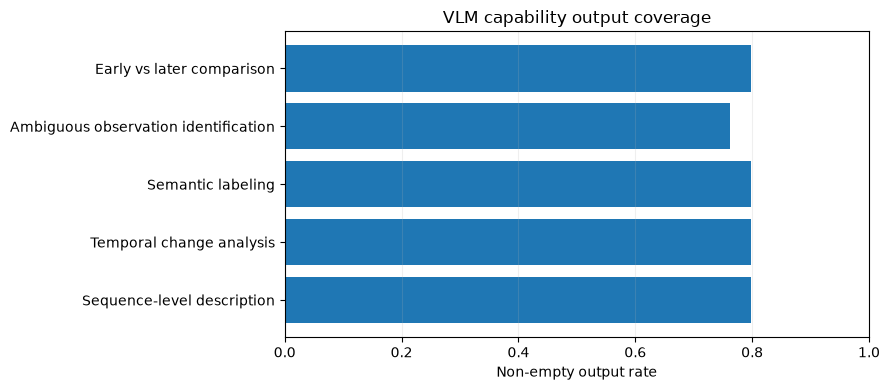

In [20]:
def present(value):
    if value is None:
        return False
    s = str(value).strip()
    return s not in ["", "[]", "null", "None", "nan"]

capability_rows = [
    ("Sequence-level description", "sequence_description"),
    ("Temporal change analysis", "temporal_changes"),
    ("Semantic labeling", "semantic_label"),
    ("Ambiguous observation identification", "ambiguous_observations"),
    ("Early vs later comparison", "early_vs_later")
]
capability_df = pd.DataFrame([
    {"capability": name, "nonempty_output_rate": float(vlm_df[col].apply(present).mean())}
    for name, col in capability_rows
])
capability_df.to_csv(OUTPUT_ROOT / "Analysis" / "capability_output_coverage.csv", index=False)
display(capability_df)

fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(capability_df["capability"], capability_df["nonempty_output_rate"])
ax.set_xlim(0, 1)
ax.set_xlabel("Non-empty output rate")
ax.set_title("VLM capability output coverage")
ax.grid(axis="x", alpha=0.2)
fig.tight_layout()
fig.savefig(OUTPUT_ROOT / "Analysis" / "capability_output_coverage.png", dpi=160)
plt.show()
plt.close(fig)


## 16. Qualitative error analysis and human-review template

In [21]:
display(vlm_df[[
    "video_id", "ground_truth_label", "normalized_vlm_label", "label_correct",
    "semantic_label_confidence", "sequence_description", "temporal_changes",
    "ambiguous_observations", "early_vs_later", "status"
]].head(20))

incorrect = vlm_df[vlm_df["valid_class_label"] & (~vlm_df["label_correct"])]
uncertain = vlm_df[~vlm_df["valid_class_label"]]
print("Incorrect emitted labels:", len(incorrect))
print("Uncertain/other labels:", len(uncertain))
display(incorrect.head(10))
display(uncertain.head(10))

review_cols = [
    "video_id", "ground_truth_label", "frame_indices", "sequence_description",
    "temporal_changes", "semantic_label", "semantic_label_confidence",
    "label_evidence", "ambiguous_observations", "early_observation",
    "later_observation", "early_vs_later", "uncertainty_notes", "raw_response"
]
review_df = vlm_df[[c for c in review_cols if c in vlm_df.columns]].copy()
review_df["human_description_quality"] = ""
review_df["human_temporal_grounding"] = ""
review_df["human_label_correct"] = ""
review_df["review_notes"] = ""
review_df.to_csv(OUTPUT_ROOT / "Analysis" / "human_review_template.csv", index=False)


,video_id,ground_truth_label,normalized_vlm_label,label_correct,semantic_label_confidence,sequence_description,temporal_changes,ambiguous_observations,early_vs_later,status
0,#20_Rhythm_clap_u_nm_np1_fr_goo_0,clap,clap,True,high,"A man is standing in front of a whiteboard, ho...","[""The man is holding a piece of paper, and the...","[""The whiteboard is visible in the background,...","The man is holding a piece of paper, and the w...",success
1,96_Meter_Bungy-Jump__Jauntal_02_dive_f_cm_np1_...,dive,uncertain/other,False,NaN,NaN,[],[],NaN,parse_error
2,A_Round_of_Applause_clap_u_cm_np1_fr_med_0,clap,clap,True,high,"A young child is sitting on a trampoline, clap...","[""The child's hands are now clapping, and he i...","[""The child is not clapping his hands.""]","The child is clapping his hands, which is a cl...",success
3,Acrobacias_de_un_fenomeno_cartwheel_f_cm_np1_f...,cartwheel,cartwheel,True,high,A person is performing a cartwheel in a grassy...,"[""The person is seen performing a cartwheel in...","[""The person is performing a cartwheel, but th...","The cartwheel is performed in both frames, but...",success
4,AgentCodyBanks_climb_stairs_f_cm_np1_fr_med_9,climb_stairs,uncertain/other,False,low,"A man is running on a beach, with ducks in the...","[[""man is running on a beach"", ""man is running...","[""man is running on a beach""]",man is running on a beach,success
5,Alex_applauding_himself_clap_u_cm_np1_fr_med_1,clap,uncertain/other,False,low,A young child is playing with blocks on the fl...,"[{""index"": 0, ""description"": ""The child is sit...","""No ambiguous observations.""","The child is playing with blocks on the floor,...",success
6,Amazing_Wall_Climber_(Must_be_Seen_to_Be_Belie...,climb,climb_stairs,False,high,A person is climbing a large stone wall. The p...,"[""The person is seen climbing the wall in the ...","[""The person is not using a rope to climb the ...",The person is seen climbing the wall in the fi...,success
7,April_09_brush_hair_u_nm_np1_ba_goo_1,brush_hair,uncertain/other,False,NaN,NaN,[],[],NaN,parse_error
8,April_09_brush_hair_u_nm_np1_ba_goo_2,brush_hair,brush_hair,True,high,A person is brushing their hair in front of a ...,"[""The person is brushing their hair in front o...","[""The person is brushing their hair in front o...",The person is brushing their hair in front of ...,success
9,Axel_beim_Klettern_an_der_Unisportwand_climb_f...,climb,uncertain/other,False,NaN,NaN,[],[],NaN,parse_error


Incorrect emitted labels: 14
Uncertain/other labels: 48


,video_id,ground_truth_label,frame_indices,status,latency_seconds,sequence_description,temporal_changes,semantic_label,semantic_label_confidence,label_evidence,...,early_observation,later_observation,early_vs_later,uncertainty_notes,parse_error,error,raw_response,normalized_vlm_label,valid_class_label,label_correct
6,Amazing_Wall_Climber_(Must_be_Seen_to_Be_Belie...,climb,"[0, 66, 100, 133, 200]",success,14.387895,A person is climbing a large stone wall. The p...,"[""The person is seen climbing the wall in the ...",climb_stairs,high,[The person is wearing a helmet and is using a...,...,The person is seen climbing the wall in the fi...,The person is seen climbing the wall in the se...,The person is seen climbing the wall in the fi...,"[""The video does not provide enough informatio...",NaN,None,"```json\n{\n ""sequence_description"": ""A perso...",climb_stairs,True,False
11,BASE_Jumping_Compilation_-_Brilliant_dive_f_cm...,dive,"[0, 12, 18, 25, 37]",success,12.230486,"Two men are on a high building, one is holding...","[""The two men are on a high building, one is h...",clap,high,"[The two men are on a high building, one is ho...",...,image 1,image 2,"The two men are on a high building, one is hol...",[],NaN,None,"```json\n{\n ""sequence_description"": ""Two men...",clap,True,False
13,BASE_Jumping_Compilation_-_Brilliant_dive_u_cm...,dive,"[0, 12, 18, 24, 36]",success,13.717894,"A person is seen wearing a helmet, holding a r...","[""The person is seen wearing a helmet, holding...",climb_stairs,high,"[The person is wearing a helmet, which is typi...",...,image 1,image 2,"The person is seen wearing a helmet, holding a...","[""The person's exact activity is not clear, bu...",NaN,None,"```json\n{\n ""sequence_description"": ""A perso...",climb_stairs,True,False
14,BIG_FISH_climb_stairs_f_nm_np1_fr_med_1,climb_stairs,"[0, 29, 58, 72, 102]",success,19.816576,A man is walking up a staircase in a house. He...,"[""The man is in the first observation, and he ...",clap,high,"[The man is wearing a suit and tie, which is a...",...,image 1,image 2,"The man is in the first observation, but he is...","[""The man's attire is not explicitly stated, b...",NaN,None,"```json\n{\n ""sequence_description"": ""A man i...",clap,True,False
23,Bristol_UCR_roof_climb_climb_f_cm_np1_ba_bad_2,climb,"[0, 100, 150, 200, 300]",success,14.864785,A man is climbing a wall in an indoor climbing...,"[{""time_point"": ""image 1"", ""description"": ""The...",climb_stairs,low,"[{'time_point': 'image 1', 'description': 'The...",...,image 1,image 2,The man is not climbing the wall in the first ...,"[{""time_point"": ""image 1"", ""description"": ""The...",NaN,None,"```json\n{\n ""sequence_description"": ""A man i...",climb_stairs,True,False
63,IAIDO_-_Training_TV-Bericht_10_2008_draw_sword...,draw_sword,"[0, 18, 27, 37, 55]",success,12.531917,"A man is kneeling on a gym floor, holding a sw...","[""The man's posture changes from a kneeling po...",clap,high,"[The man is holding a sword, which is a martia...",...,The man is kneeling on the gym floor.,The man is holding a sword and performing a ma...,The man's posture changes from a kneeling posi...,"[""The video does not provide enough informatio...",NaN,None,"```json\n{\n ""sequence_description"": ""A man i...",clap,True,False
80,Marc_-_K_pfer_-_1m_dive_f_cm_np1_le_bad_0,dive,"[0, 11, 16, 22, 33]",success,15.023591,A man is seen running up a diving board and ju...,"[""The man is seen running up a diving board an...",clap,high,[The man is seen running up a diving board and...,...,The man is seen running up a diving board and ...,The man is seen running up a diving board and ...,The man is seen running up a diving board and ...,[],NaN,None,"```json\n{\n ""sequence_description"": ""A man i...",clap,True,False
81,Master_Pena_Iaido_Katas_draw_sword_f_nm_np1_fr...,draw_sword,"[0, 22, 33, 44, 66]",success,15.008187,A person is standing in a room with a blue flo...,"[""The person is holding a sword and is in a ma...",clap,high,[T

,video_id,ground_truth_label,frame_indices,status,latency_seconds,sequence_description,temporal_changes,semantic_label,semantic_label_confidence,label_evidence,...,early_observation,later_observation,early_vs_later,uncertainty_notes,parse_error,error,raw_response,normalized_vlm_label,valid_class_label,label_correct
1,96_Meter_Bungy-Jump__Jauntal_02_dive_f_cm_np1_...,dive,"[0, 34, 51, 68, 102]",parse_error,16.983295,NaN,[],NaN,NaN,None,...,NaN,NaN,NaN,[],"JSON parse error: Expecting ',' delimiter: lin...",None,"```json\n{\n ""sequence_description"": ""A perso...",uncertain/other,False,False
4,AgentCodyBanks_climb_stairs_f_cm_np1_fr_med_9,climb_stairs,"[0, 18, 28, 37, 56]",success,16.680112,"A man is running on a beach, with ducks in the...","[[""man is running on a beach"", ""man is running...",uncertain/other,low,[man is running on a beach],...,man is running on a beach,man is running on a beach,man is running on a beach,"[""The video does not provide enough informatio...",NaN,None,"```json\n{\n ""sequence_description"": ""A man i...",uncertain/other,False,False
5,Alex_applauding_himself_clap_u_cm_np1_fr_med_1,clap,"[0, 22, 33, 44, 66]",success,15.135051,A young child is playing with blocks on the fl...,"[{""index"": 0, ""description"": ""The child is sit...",uncertain/other,low,"The child is playing with blocks on the floor,...",...,The child is sitting on the floor with a toy i...,"The child is playing with blocks on the floor,...","The child is playing with blocks on the floor,...","""The child's actions and the toys in the backg...",NaN,None,"```json\n{\n ""sequence_description"": ""A young...",uncertain/other,False,False
7,April_09_brush_hair_u_nm_np1_ba_goo_1,brush_hair,"[0, 112, 168, 225, 337]",parse_error,15.682098,NaN,[],NaN,NaN,None,...,NaN,NaN,NaN,[],No JSON object in response,None,"```json\n{\n ""sequence_description"": ""A woman...",uncertain/other,False,False
9,Axel_beim_Klettern_an_der_Unisportwand_climb_f...,climb,"[0, 47, 71, 94, 142]",parse_error,15.785807,NaN,[],NaN,NaN,None,...,NaN,NaN,NaN,[],No JSON object in response,None,"```json\n{\n ""sequence_description"": ""A man i...",uncertain/other,False,False
10,BASE_JUMPING_COMPILATION_PART_3_AMAZING!!!!!!!...,dive,"[0, 14, 21, 28, 42]",success,13.341852,A person is standing on a rooftop with their a...,"[""The person is standing on a rooftop with the...",uncertain/other,high,[The person is standing on a rooftop with thei...,...,image 1,image 5,The person is standing on a rooftop with their...,"[""The image is not clear, and the person's arm...",NaN,None,"```json\n{\n ""sequence_description"": ""A perso...",uncertain/other,False,False
12,BASE_Jumping_Compilation_-_Brilliant_dive_f_cm...,dive,"[0, 13, 19, 26, 39]",success,12.152116,A person is seen jumping off a cliff into the ...,"[""The person is seen jumping off a cliff into ...",jumping,high,[The person is jumping off a cliff into the wa...,...,image 1,image 5,The person is jumping off a cliff into the wat...,[],NaN,None,"```json\n{\n ""sequence_description"": ""A perso...",uncertain/other,False,False
17,Blowing_Bubbles!_chew_h_nm_np1_fr_goo_2,chew,"[0, 42, 64, 85, 128]",success,13.852754,A young girl with long red hair is looking up ...,"[""The girl's hair color changes from red to bl...",uncertain/other,low,[The girl's hair color is not specified in the...,...,image 1,image 5,The girl's hair color changes from red to blonde.,"[""The video does not provide enough informatio...",NaN,None,"```json\n{\n ""sequence_description"": ""A young...",uncertain/other,False,False
18,Bodenturnen_2004_cartwheel_f_cm_np1_le_med_4,cartwheel,"[0, 12, 18, 24, 36]",parse_error,15.155520,NaN,[],NaN,NaN,None,...,NaN,NaN,NaN,[],No JSON object in response,None,"```json\n{\n ""sequence_description"": ""A gymna...",uncertain/other,False,False
32,Cartwheel_Competition_cartwheel_f_cm_np1_le_med_4,cartwheel,"[0, 22, 33, 44, 66]",parse_error,16.316698,NaN,[],NaN,NaN,None,...,NaN,NaN,NaN,[],No JSON object in response,None,"```json\n{\n "

## 17. Runtime and provenance

In [22]:
successful = vlm_df[vlm_df["status"] == "success"]
provenance = {
    "stage": 6,
    "model_id": MODEL_ID,
    "model_family": MODEL_FAMILY,
    "quantization": QUANTIZATION,
    "model_load_seconds": model_load_seconds,
    "evaluated_videos": len(vlm_df),
    "successful_structured_outputs": int((vlm_df["status"] == "success").sum()),
    "parse_errors": int((vlm_df["status"] == "parse_error").sum()),
    "runtime_errors": int((vlm_df["status"] == "error").sum()),
    "median_inference_seconds": float(successful["latency_seconds"].median()) if len(successful) else None,
    "mean_inference_seconds": float(successful["latency_seconds"].mean()) if len(successful) else None,
    "frames_per_video": FRAMES_PER_VIDEO,
    "max_new_tokens": MAX_NEW_TOKENS,
    "temperature": TEMPERATURE,
    "backend": "Apple Silicon MLX",
    "python": platform.python_version(),
    "platform": platform.platform(),
    "split_file": str(split_path),
    "frame_manifest": str(manifest_path),
    "test_split_size": len(TEST_IDS),
    "accessible_test_videos": len(records),
    "full_test_run_enabled": RUN_FULL_TEST_SET,
    "max_test_videos": MAX_TEST_VIDEOS,
    "seed": SEED,
    "fine_tuning": False
}
(OUTPUT_ROOT / "Logs" / "vlm_provenance.json").write_text(json.dumps(provenance, indent=2))
pd.DataFrame([provenance]).to_csv(OUTPUT_ROOT / "Logs" / "vlm_provenance.csv", index=False)
display(pd.DataFrame([provenance]))


,stage,model_id,model_family,quantization,model_load_seconds,evaluated_videos,successful_structured_outputs,parse_errors,runtime_errors,median_inference_seconds,...,python,platform,split_file,frame_manifest,test_split_size,accessible_test_videos,full_test_run_enabled,max_test_videos,seed,fine_tuning
0,6,mlx-community/Qwen2-VL-2B-Instruct-4bit,Qwen2.5-VL-3B-Instruct,4-bit MLX,335.437331,143,114,29,0,13.204461,...,3.11.15,macOS-15.7.4-arm64-arm-64bit,/Users/vanshikaarora/Desktop/Tracking/Single-m...,/Users/vanshikaarora/Desktop/Tracking/embeddin...,143,143,True,None,42,False


## 18. Final interpretation guide and expected artifacts

Output folder:

```text
Tracking/
├── embeddings/
├── Single-multiframe/
├── Temporal-Evaluation/
└── VLM-Evaluation/
    ├── Pilot/
    │   ├── vlm_pilot_results.csv
    │   └── vlm_pilot_raw.json
    ├── VLM_Outputs/
    │   ├── vlm_test_results.csv
    │   └── vlm_test_results_raw.json
    ├── Classifier_Comparison/
    │   ├── vlm_vs_visual_classifier.csv
    │   └── per_video_comparison.csv
    ├── Analysis/
    │   ├── semantic_label_metrics.csv
    │   ├── semantic_label_per_class.csv
    │   ├── capability_output_coverage.csv
    │   ├── capability_output_coverage.png
    │   └── human_review_template.csv
    └── Logs/
        ├── missing_frame_paths.csv
        └── vlm_provenance.json / .csv
```

### Where the VLM adds value

- **Visual embedding classifier:** fast, consistent closed-set classification and class scores; does not naturally explain changes between observations.
- **VLM:** natural-language sequence descriptions, early/later comparisons, semantic context, and explicit uncertainty/ambiguity notes.
- **Trade-offs:** slower and more memory-intensive inference; generated descriptions may hallucinate or misread motion; human review is needed.
- **Complementary design:** use the visual classifier for efficient predictions and call the VLM on selected sequences where explanation, ambiguity analysis, or richer semantic context is valuable.

### Research guardrails

1. VLM semantic-label accuracy is not directly comparable to the supervised classifier as a fair model benchmark: the input format, training and prompting differ.
2. A non-empty temporal-change description does not prove that the described change is real. Inspect outputs against contact sheets.
3. The model sees only five sampled frames, not the full continuous video. Describe it as sampled-sequence analysis.
4. Report valid-output rate and label coverage alongside conditional accuracy.
5. No fine-tuning is performed.
6. Preserve the raw JSON responses and human-review sheet as evidence.

**Stage 6 is complete when the pilot passes, the intended test videos are processed, and the saved outputs have been manually spot-checked against the displayed frames.**
